# Investigating the Evolution and Distribution of Antibiotic Resistance Among Selected *Escherichia coli* Strains Using Comparative Genomics

**Strathmore University | Group 2**

### Group Members

| Student Number | Name |
|---|---|
| 160588 | Kirui Sharlet Jerono |
| 166531 | Deborah Kaburu |
| 166488 | Bwibo Ethan Nimrod |
| 166386 | Githinji Nathan Rugo |
| 162831 | Wangeci Brown Kamau |
| 165852 | Njenga Martin Njuguna |

### Introduction

This research investigates the distribution and evolution of antibiotic resistance among selected *Escherichia coli* strains using comparative genomics. The study aims to identify differences in antibiotic resistance genes, examine genomic variation, and explore evolutionary relationships among the strains.

### Data Source and Biological Data Type

**Source:** [NCBI RefSeq Genome Database](https://www.ncbi.nlm.nih.gov/datasets/genome/)

**Biological data:** Genomic DNA sequences in FASTA format, accompanied by assembly metadata in JSONL format.

**Dataset:** Nine selected *E. coli* genome assemblies comprising 15 DNA sequence records.

### Notebook Scope

This notebook covers **Stage 2: Dataset Description** and **Stage 3: Data Preparation and Exploratory Data Analysis**, including sequence quality assessment, descriptive statistics, nucleotide composition analysis, and genomic visualisations.

In [1]:

!pip -q install biopython pandas matplotlib seaborn


In [2]:

from google.colab import files

uploaded = files.upload()


Saving ncbi_dataset.zip to ncbi_dataset.zip


In [3]:

import zipfile
from pathlib import Path

zip_name = next(iter(uploaded))

extract_path = Path("/content/ecoli_dataset")
extract_path.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!\n")

for file in sorted(extract_path.rglob("*")):
    if file.is_file():
        print(file.relative_to(extract_path))


Dataset extracted successfully!

README.md
md5sum.txt
ncbi_dataset/data/GCA_000005845.2/GCA_000005845.2_ASM584v2_genomic.fna
ncbi_dataset/data/GCF_000005845.2/GCF_000005845.2_ASM584v2_genomic.fna
ncbi_dataset/data/assembly_data_report.jsonl
ncbi_dataset/data/data_summary.tsv
ncbi_dataset/data/dataset_catalog.json


In [4]:

fasta_files = sorted(
    list(extract_path.rglob("*.fna")) +
    list(extract_path.rglob("*.fasta"))
)

metadata_files = list(
    extract_path.rglob("assembly_data_report.jsonl")
)

print("Number of genome FASTA files:", len(fasta_files))
print("Number of metadata reports:", len(metadata_files))

print("\nGenome files found:")
for file in fasta_files:
    print(file.name, "|", file.parent.name)

if not fasta_files:
    print("\nNo genome FASTA files found.")
    print("Check whether genomic sequences were included in the NCBI download.")


Number of genome FASTA files: 2
Number of metadata reports: 1

Genome files found:
GCA_000005845.2_ASM584v2_genomic.fna | GCA_000005845.2
GCF_000005845.2_ASM584v2_genomic.fna | GCF_000005845.2


In [5]:

from Bio import SeqIO
import pandas as pd

# Keep the RefSeq assembly only
refseq_files = [
    file for file in fasta_files
    if file.parent.name.startswith("GCF_")
]

print("RefSeq genome files:", len(refseq_files))

records = []

for file in refseq_files:
    for record in SeqIO.parse(str(file), "fasta"):
        dna = str(record.seq).upper()

        records.append({
            "assembly_accession": file.parent.name,
            "sequence_id": record.id,
            "description": record.description,
            "sequence_length": len(dna),
            "a_count": dna.count("A"),
            "t_count": dna.count("T"),
            "g_count": dna.count("G"),
            "c_count": dna.count("C"),
            "n_count": dna.count("N")
        })

df = pd.DataFrame(records)

print("\nNumber of DNA sequence records:", len(df))
display(df.head())


RefSeq genome files: 1

Number of DNA sequence records: 1


,assembly_accession,sequence_id,description,sequence_length,a_count,t_count,g_count,c_count,n_count
0,GCF_000005845.2,NC_000913.3,NC_000913.3 Escherichia coli str. K-12 substr....,4641652,1142742,1141382,1177437,1180091,0


In [6]:

# Calculate GC content for each sequence
valid_bases = (
    df["a_count"] +
    df["t_count"] +
    df["g_count"] +
    df["c_count"]
)

df["gc_percent"] = (
    (df["g_count"] + df["c_count"])
    / valid_bases.replace(0, float("nan"))
) * 100

print("Genome sequence statistics:")
display(
    df[[
        "assembly_accession",
        "sequence_id",
        "sequence_length",
        "gc_percent",
        "n_count"
    ]]
)


Genome sequence statistics:


,assembly_accession,sequence_id,sequence_length,gc_percent,n_count
0,GCF_000005845.2,NC_000913.3,4641652,50.79071,0


In [7]:

print("Duplicate sequence identifiers:")
print(
    df.duplicated(
        subset=["assembly_accession", "sequence_id"]
    ).sum()
)

print("\nMissing values:")
display(df.isnull().sum())

print("\nBasic descriptive statistics:")
display(
    df[[
        "sequence_length",
        "gc_percent",
        "n_count"
    ]].describe()
)


Duplicate sequence identifiers:
0

Missing values:


,0
assembly_accession,0
sequence_id,0
description,0
sequence_length,0
a_count,0
t_count,0
g_count,0
c_count,0
n_count,0
gc_percent,0



Basic descriptive statistics:


,sequence_length,gc_percent,n_count
count,1.0,1.00000,1.0
mean,4641652.0,50.79071,0.0
std,NaN,NaN,NaN
min,4641652.0,50.79071,0.0
25%,4641652.0,50.79071,0.0
50%,4641652.0,50.79071,0.0
75%,4641652.0,50.79071,0.0
max,4641652.0,50.79071,0.0


### 3.1 Data Preparation and Quality Assessment

The downloaded NCBI dataset initially contained both GenBank (GCA) and RefSeq (GCF) assembly records for *Escherichia coli* K-12 MG1655.

Because these records represent the same bacterial strain and assembly, retaining both would introduce redundant information into the dataset. The RefSeq assembly was therefore selected for subsequent analysis.

The genomic sequence was loaded using Biopython, and relevant characteristics were extracted, including sequence length, nucleotide composition and GC content.

Additional checks were performed to identify duplicate sequence identifiers and missing values. The results of these checks were used to assess whether further preprocessing was necessary.

In [9]:

import json

metadata_rows = []

for metadata_file in metadata_files:
    with open(metadata_file, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                metadata_rows.append(json.loads(line))

metadata_df = pd.json_normalize(metadata_rows)

print("Number of metadata records:", len(metadata_df))

print("\nAvailable metadata columns:")
for column in metadata_df.columns:
    print(column)

print("\nFirst metadata records:")
display(metadata_df.head())


Number of metadata records: 2

Available metadata columns:
currentAccession
accession
pairedAccession
sourceDatabase
assemblyInfo.assemblyLevel
assemblyInfo.assemblyName
assemblyInfo.assemblyType
assemblyInfo.submitter
assemblyInfo.refseqCategory
assemblyInfo.bioprojectLineage
assemblyInfo.biosample.accession
assemblyInfo.biosample.lastUpdated
assemblyInfo.biosample.publicationDate
assemblyInfo.biosample.submissionDate
assemblyInfo.biosample.sampleIds
assemblyInfo.biosample.description.title
assemblyInfo.biosample.description.organism.taxId
assemblyInfo.biosample.description.organism.organismName
assemblyInfo.biosample.owner.name
assemblyInfo.biosample.models
assemblyInfo.biosample.bioprojects
assemblyInfo.biosample.package
assemblyInfo.biosample.attributes
assemblyInfo.biosample.status.status
assemblyInfo.biosample.status.when
assemblyInfo.biosample.strain
assemblyInfo.assemblyStatus
assemblyInfo.pairedAssembly.accession
assemblyInfo.pairedAssembly.status
assemblyInfo.pairedAssembly.a

,currentAccession,accession,pairedAccession,sourceDatabase,assemblyInfo.assemblyLevel,assemblyInfo.assemblyName,assemblyInfo.assemblyType,assemblyInfo.submitter,assemblyInfo.refseqCategory,assemblyInfo.bioprojectLineage,...,averageNucleotideIdentity.bestAniMatch.assembly,averageNucleotideIdentity.bestAniMatch.organismName,averageNucleotideIdentity.bestAniMatch.category,averageNucleotideIdentity.bestAniMatch.ani,averageNucleotideIdentity.bestAniMatch.assemblyCoverage,averageNucleotideIdentity.bestAniMatch.typeAssemblyCoverage,averageNucleotideIdentity.comment,organism.taxId,organism.organismName,organism.infraspecificNames.strain
0,GCA_000005845.2,GCA_000005845.2,GCF_000005845.2,SOURCE_DATABASE_GENBANK,Complete Genome,ASM584v2,haploid,Univ. Wisconsin,reference genome,"[{'bioprojects': [{'accession': 'PRJNA225', 't...",...,GCA_000210475.1,Escherichia coli,claderef,99.46,94.38,82.26,na,511145,Escherichia coli str. K-12 substr. MG1655,K-12 substr. MG1655
1,GCF_000005845.2,GCF_000005845.2,GCA_000005845.2,SOURCE_DATABASE_REFSEQ,Complete Genome,ASM584v2,haploid,Univ. Wisconsin,reference genome,"[{'bioprojects': [{'accession': 'PRJNA225', 't...",...,GCA_000210475.1,Escherichia coli,claderef,99.46,94.38,82.26,na,511145,Escherichia coli str. K-12 substr. MG1655,K-12 substr. MG1655


In [10]:

# Select the RefSeq assembly
refseq_metadata = metadata_df[
    metadata_df["sourceDatabase"] == "SOURCE_DATABASE_REFSEQ"
].copy()

# Relevant biological and assembly metadata
selected_columns = [
    "accession",
    "organism.organismName",
    "organism.infraspecificNames.strain",
    "assemblyInfo.assemblyLevel",
    "assemblyInfo.assemblyName",
    "assemblyInfo.releaseDate",
    "assemblyStats.totalSequenceLength",
    "assemblyStats.numberOfContigs",
    "assemblyStats.gcPercent",
    "annotationInfo.stats.geneCounts.total",
    "annotationInfo.stats.geneCounts.proteinCoding",
    "assemblyInfo.biosample.accession"
]

# Keep only fields available in the dataset
available_columns = [
    col for col in selected_columns
    if col in refseq_metadata.columns
]

metadata_clean = refseq_metadata[
    available_columns
].copy()

display(metadata_clean.T)


,1
accession,GCF_000005845.2
organism.organismName,Escherichia coli str. K-12 substr. MG1655
organism.infraspecificNames.strain,K-12 substr. MG1655
assemblyInfo.assemblyLevel,Complete Genome
assemblyInfo.assemblyName,ASM584v2
assemblyInfo.releaseDate,2013-09-26
assemblyStats.totalSequenceLength,4641652
assemblyStats.numberOfContigs,1
assemblyStats.gcPercent,51
annotationInfo.stats.geneCounts.total,4651


In [11]:

print("Selected metadata records:", len(metadata_clean))

print("\nDuplicate accessions:")
print(metadata_clean["accession"].duplicated().sum())

print("\nMissing values:")
display(metadata_clean.isnull().sum())

print("\nAssembly levels:")
display(
    metadata_clean["assemblyInfo.assemblyLevel"].value_counts()
)

print("\nSelected metadata:")
display(metadata_clean)


Selected metadata records: 1

Duplicate accessions:
0

Missing values:


,0
accession,0
organism.organismName,0
organism.infraspecificNames.strain,0
assemblyInfo.assemblyLevel,0
assemblyInfo.assemblyName,0
assemblyInfo.releaseDate,0
assemblyStats.totalSequenceLength,0
assemblyStats.numberOfContigs,0
assemblyStats.gcPercent,0
annotationInfo.stats.geneCounts.total,0



Assembly levels:


,count
assemblyInfo.assemblyLevel,
Complete Genome,1



Selected metadata:


,accession,organism.organismName,organism.infraspecificNames.strain,assemblyInfo.assemblyLevel,assemblyInfo.assemblyName,assemblyInfo.releaseDate,assemblyStats.totalSequenceLength,assemblyStats.numberOfContigs,assemblyStats.gcPercent,annotationInfo.stats.geneCounts.total,annotationInfo.stats.geneCounts.proteinCoding,assemblyInfo.biosample.accession
1,GCF_000005845.2,Escherichia coli str. K-12 substr. MG1655,K-12 substr. MG1655,Complete Genome,ASM584v2,2013-09-26,4641652,1,51,4651,4290,SAMN02604091


In [13]:

import pandas as pd

# STEP 1: Get values calculated from the FASTA sequence
calculated = df[[
    "assembly_accession",
    "sequence_length",
    "gc_percent"
]].copy()

# STEP 2: Get values reported by NCBI
reported = metadata_clean[[
    "accession",
    "assemblyStats.totalSequenceLength",
    "assemblyStats.gcPercent"
]].copy()

# STEP 3: Convert columns into numeric data types
calculated["sequence_length"] = pd.to_numeric(
    calculated["sequence_length"],
    errors="coerce"
)

calculated["gc_percent"] = pd.to_numeric(
    calculated["gc_percent"],
    errors="coerce"
)

reported["assemblyStats.totalSequenceLength"] = pd.to_numeric(
    reported["assemblyStats.totalSequenceLength"],
    errors="coerce"
)

reported["assemblyStats.gcPercent"] = pd.to_numeric(
    reported["assemblyStats.gcPercent"],
    errors="coerce"
)

# STEP 4: Merge the FASTA and NCBI metadata
comparison = calculated.merge(
    reported,
    left_on="assembly_accession",
    right_on="accession",
    how="inner"
)

# STEP 5: Calculate differences
comparison["length_difference"] = (
    comparison["sequence_length"] -
    comparison["assemblyStats.totalSequenceLength"]
)

comparison["gc_difference"] = (
    comparison["gc_percent"] -
    comparison["assemblyStats.gcPercent"]
)

# STEP 6: Display the results
print("FASTA vs NCBI Metadata Comparison")
display(comparison)

print("\nData types after conversion:")
print(comparison.dtypes)


FASTA vs NCBI Metadata Comparison


,assembly_accession,sequence_length,gc_percent,accession,assemblyStats.totalSequenceLength,assemblyStats.gcPercent,length_difference,gc_difference
0,GCF_000005845.2,4641652,50.79071,GCF_000005845.2,4641652,51,0,-0.20929



Data types after conversion:
assembly_accession                    object
sequence_length                        int64
gc_percent                           float64
accession                             object
assemblyStats.totalSequenceLength      int64
assemblyStats.gcPercent                int64
length_difference                      int64
gc_difference                        float64
dtype: object


### 3.1 Validation of Genomic Sequence Data

The genomic sequence measurements calculated using Biopython were compared with the corresponding assembly statistics reported by NCBI.

The FASTA sequence contained 4,641,652 base pairs, which matched the NCBI-reported sequence length exactly, resulting in a difference of zero base pairs.

The calculated GC content was 50.79071%, compared with the NCBI-reported value of 51%. The difference of 0.20929 percentage points is consistent with rounding of the GC percentage in the NCBI metadata.

These results indicate that the calculated sequence measurements are consistent with the NCBI assembly statistics. No modifications to the underlying DNA sequence were required.

The validation supports the use of this reference genome for subsequent descriptive analysis and comparative genomic exploration.

In [14]:

# Step 13: Install the official NCBI Datasets CLI

!curl -L -s --fail \
  https://ftp.ncbi.nlm.nih.gov/pub/datasets/command-line/v2/linux-amd64/datasets \
  -o /usr/local/bin/datasets

!chmod +x /usr/local/bin/datasets

# Confirm installation
!datasets version


datasets version: 18.40.0


In [15]:

# Step 14: Create a reproducible accession list

accessions = [
    "GCF_000005845.2",
    "GCF_000010245.2",
    "GCF_000006665.1",
    "GCF_000008865.2",
    "GCF_000007445.1",
    "GCF_000013265.1",
    "GCF_000013305.1",
    "GCF_000014845.1",
    "GCF_000017765.1",
    "GCF_000017925.1"
]

with open("/content/ecoli_accessions.txt", "w") as f:
    f.write("\n".join(accessions) + "\n")

print("Requested assemblies:", len(accessions))
print(open("/content/ecoli_accessions.txt").read())


Requested assemblies: 10
GCF_000005845.2
GCF_000010245.2
GCF_000006665.1
GCF_000008865.2
GCF_000007445.1
GCF_000013265.1
GCF_000013305.1
GCF_000014845.1
GCF_000017765.1
GCF_000017925.1



In [16]:

# Download genome sequences and assembly metadata
!datasets download genome accession \
  --inputfile /content/ecoli_accessions.txt \
  --include genome \
  --filename /content/ecoli_10_genomes.zip


Downloading: /content/ecoli_10_genomes.zip    4.17kB 23.6MB/s
Downloading: /content/ecoli_10_genomes.zip    4.17kB 23.6MB/s
Downloading: /content/ecoli_10_genomes.zip    4.17kB 23.6MB/s
Downloading: /content/ecoli_10_genomes.zip    12.1kB 433kB/s
Downloading: /content/ecoli_10_genomes.zip    12.1kB 433kB/s
Downloading: /content/ecoli_10_genomes.zip    65.5kB 1.2MB/s
Downloading: /content/ecoli_10_genomes.zip    65.5kB 1.2MB/s
Downloading: /content/ecoli_10_genomes.zip    65.5kB 1.2MB/s
Downloading: /content/ecoli_10_genomes.zip    197kB 2.39MB/s
Downloading: /content/ecoli_10_genomes.zip    197kB 2.39MB/s
Downloading: /content/ecoli_10_genomes.zip    229kB 2.1MB/s
Downloading: /content/ecoli_10_genomes.zip    393kB 3.56MB/s
Downloading: /content/ecoli_10_genomes.zip    393kB 3.56MB/s
Downloading: /content/ecoli_10_genomes.zip    819kB 5.86MB/s
Downloading: /content/ecoli_10_genomes.zip    852kB 6.06MB/s
Downloading: /content/ecoli_10_genomes.zip    852kB 6.06MB/s
Downloading: /content/

In [17]:

import zipfile
import json
import pandas as pd
from pathlib import Path
from Bio import SeqIO

new_folder = Path("/content/ecoli_10_genomes")
new_folder.mkdir(exist_ok=True)

with zipfile.ZipFile("/content/ecoli_10_genomes.zip") as z:
    z.extractall(new_folder)

new_fasta_files = sorted(new_folder.rglob("*.fna"))
new_metadata_files = list(
    new_folder.rglob("assembly_data_report.jsonl")
)

print("Genome FASTA files:", len(new_fasta_files))
print("Metadata reports:", len(new_metadata_files))

for path in new_fasta_files:
    print(path.parent.name, "-", path.name)

# Check requested vs downloaded assembly accessions
downloaded = {p.parent.name for p in new_fasta_files}
missing = set(accessions) - downloaded

print("\nRequested:", len(accessions))
print("Downloaded:", len(downloaded))
print("Missing:", sorted(missing))

if missing:
    print("Investigate unavailable accessions before proceeding.")


Genome FASTA files: 9
Metadata reports: 1
GCF_000005845.2 - GCF_000005845.2_ASM584v2_genomic.fna
GCF_000006665.1 - GCF_000006665.1_ASM666v1_genomic.fna
GCF_000007445.1 - GCF_000007445.1_ASM744v1_genomic.fna
GCF_000008865.2 - GCF_000008865.2_ASM886v2_genomic.fna
GCF_000010245.2 - GCF_000010245.2_ASM1024v1_genomic.fna
GCF_000013265.1 - GCF_000013265.1_ASM1326v1_genomic.fna
GCF_000013305.1 - GCF_000013305.1_ASM1330v1_genomic.fna
GCF_000014845.1 - GCF_000014845.1_ASM1484v1_genomic.fna
GCF_000017765.1 - GCF_000017765.1_ASM1776v1_genomic.fna

Requested: 10
Downloaded: 9
Missing: ['GCF_000017925.1']
Investigate unavailable accessions before proceeding.


In [18]:

metadata_rows = []

for path in new_metadata_files:
    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                metadata_rows.append(json.loads(line))

all_metadata = pd.json_normalize(metadata_rows)

# Select only RefSeq records
all_metadata = all_metadata[
    all_metadata["accession"].str.startswith("GCF_")
].copy()

fields = [
    "accession",
    "organism.organismName",
    "organism.infraspecificNames.strain",
    "assemblyInfo.assemblyLevel",
    "assemblyStats.totalSequenceLength",
    "assemblyStats.gcPercent",
    "assemblyStats.numberOfContigs",
    "assemblyInfo.biosample.accession"
]

available = [c for c in fields if c in all_metadata.columns]

display(all_metadata[available])

print("RefSeq metadata records:", len(all_metadata))


,accession,organism.organismName,organism.infraspecificNames.strain,assemblyInfo.assemblyLevel,assemblyStats.totalSequenceLength,assemblyStats.gcPercent,assemblyStats.numberOfContigs,assemblyInfo.biosample.accession
0,GCF_000005845.2,Escherichia coli str. K-12 substr. MG1655,K-12 substr. MG1655,Complete Genome,4641652,51.0,1,SAMN02604091
1,GCF_000006665.1,Escherichia coli O157:H7 str. EDL933,EDL933,Chromosome,5620522,50.5,3,SAMN02604092
2,GCF_000007445.1,Escherichia coli CFT073,CFT073,Complete Genome,5231428,50.5,1,SAMN02604094
3,GCF_000008865.2,Escherichia coli O157:H7 str. Sakai,Sakai substr. RIMD 0509952,Complete Genome,5594605,50.5,3,SAMN01911278
4,GCF_000010245.2,Escherichia coli str. K-12 substr. W3110,K-12 substr. W3110,Complete Genome,4646332,51.0,1,SAMD00061081
5,GCF_000013265.1,Escherichia coli UTI89,UTI89,Complete Genome,5179971,50.5,2,SAMN00000110
6,GCF_000013305.1,Escherichia coli 536,536,Complete Genome,4938920,50.5,1,SAMN02604181
7,GCF_000014845.1,Escherichia coli APEC O1,APEC O1,Complete Genome,5497653,50.5,3,SAMN02603424
8,GCF_000017765.1,Escherichia coli HS,HS,Complete Genome,4643538,51.0,1,SAMN02604037


RefSeq metadata records: 9


In [19]:

# Step 16A: Identify requested assemblies
# that are missing from the metadata

requested = set(accessions)

found = set(
    all_metadata["accession"].dropna()
)

missing_accessions = sorted(requested - found)

print("Requested genomes:", len(requested))
print("Found in metadata:", len(found))

print("\nMissing accession(s):")
for accession in missing_accessions:
    print(accession)


Requested genomes: 10
Found in metadata: 9

Missing accession(s):
GCF_000017925.1


In [20]:

# Step 16B: Check missing accession on NCBI

!datasets summary genome accession GCF_000017925.1


{"total_count": 0}


In [21]:

# Step 16C: Match FASTA files to metadata

fasta_accessions = {
    path.parent.name
    for path in new_fasta_files
}

metadata_accessions = set(
    all_metadata["accession"].dropna()
)

print("FASTA assemblies:", len(fasta_accessions))
print("Metadata assemblies:", len(metadata_accessions))

print("\nMetadata without FASTA:")
print(sorted(metadata_accessions - fasta_accessions))

print("\nFASTA without metadata:")
print(sorted(fasta_accessions - metadata_accessions))


FASTA assemblies: 9
Metadata assemblies: 9

Metadata without FASTA:
[]

FASTA without metadata:
[]


### Verification of Downloaded Genome Assemblies

The initial multi-genome download produced metadata records for nine distinct *Escherichia coli* assemblies from NCBI RefSeq.

Eight assemblies were classified as Complete Genome, while one, *E. coli* O157:H7 EDL933, was classified at the Chromosome assembly level.

The number of contigs reported across assemblies ranged from one to three, indicating differences in assembly structure.

One of the ten requested assembly accessions was absent from the downloaded metadata. This discrepancy was identified for further investigation before completing the comparative descriptive analysis.

In [22]:

# Step 17: Load all verified genome sequences

from Bio import SeqIO
import pandas as pd

verified_accessions = (
    fasta_accessions & metadata_accessions
)

sequence_records = []

for fasta_path in new_fasta_files:

    accession = fasta_path.parent.name

    if accession not in verified_accessions:
        continue

    for record in SeqIO.parse(str(fasta_path), "fasta"):

        dna = str(record.seq).upper()

        a = dna.count("A")
        t = dna.count("T")
        g = dna.count("G")
        c = dna.count("C")
        n = dna.count("N")

        valid_bases = a + t + g + c

        gc_percent = (
            ((g + c) / valid_bases) * 100
            if valid_bases > 0
            else float("nan")
        )

        sequence_records.append({
            "assembly_accession": accession,
            "sequence_id": record.id,
            "description": record.description,
            "sequence_length": len(dna),
            "a_count": a,
            "t_count": t,
            "g_count": g,
            "c_count": c,
            "n_count": n,
            "other_base_count": len(dna) - valid_bases - n,
            "gc_percent": gc_percent
        })

sequences_df = pd.DataFrame(sequence_records)

print("Number of DNA sequence records:", len(sequences_df))

print(
    "Number of distinct genome assemblies:",
    sequences_df["assembly_accession"].nunique()
)

display(sequences_df.head(10))


Number of DNA sequence records: 15
Number of distinct genome assemblies: 9


,assembly_accession,sequence_id,description,sequence_length,a_count,t_count,g_count,c_count,n_count,other_base_count,gc_percent
0,GCF_000005845.2,NC_000913.3,NC_000913.3 Escherichia coli str. K-12 substr....,4641652,1142742,1141382,1177437,1180091,0,0,50.790710
1,GCF_000006665.1,NC_002655.2,NC_002655.2 Escherichia coli O157:H7 str. EDL9...,5528445,1369964,1366445,1391726,1393669,4228,2413,50.443569
2,GCF_000006665.1,NC_007414.1,NC_007414.1 Escherichia coli O157:H7 str. EDL9...,92077,24693,23523,23728,20133,0,0,47.635131
3,GCF_000007445.1,NC_004431.1,"NC_004431.1 Escherichia coli CFT073, complete ...",5231428,1297551,1293044,1319228,1321325,87,193,50.477505
4,GCF_000008865.2,NC_002695.2,NC_002695.2 Escherichia coli O157:H7 str. Saka...,5498578,1361525,1358234,1392563,1386256,0,0,50.537048
5,GCF_000008865.2,NC_002127.1,NC_002127.1 Escherichia coli O157:H7 str. Saka...,3306,797,1074,743,692,0,0,43.405929
6,GCF_000008865.2,NC_002128.1,NC_002128.1 Escherichia coli O157:H7 str. Saka...,92721,24870,23716,23868,20267,0,0,47.599789
7,GCF_000010245.2,NC_007779.1,NC_007779.1 Escherichia coli str. K-12 substr....,4646332,1142182,1143833,1181238,1179079,0,0,50.799577
8,GCF_000013265.1,NC_007946.1,"NC_007946.1 Escherichia coli UTI89, complete s...",5065741,1250197,1252067,1279155,1284322,0,0,50.604186
9,GCF_000013265.1,NC_007941.1,NC_007941.1 Escherichia coli UTI89 plasmid pUT...,114230,28225,27719,30767,27519,0,0,51.025125


In [23]:

# Step 18: Summarise sequences at assembly level

genome_df = (
    sequences_df
    .groupby("assembly_accession")
    .agg(
        total_length_bp=("sequence_length", "sum"),
        sequence_count=("sequence_id", "count"),
        a_count=("a_count", "sum"),
        t_count=("t_count", "sum"),
        g_count=("g_count", "sum"),
        c_count=("c_count", "sum"),
        n_count=("n_count", "sum"),
        other_base_count=("other_base_count", "sum")
    )
    .reset_index()
)

valid_bases = (
    genome_df["a_count"] +
    genome_df["t_count"] +
    genome_df["g_count"] +
    genome_df["c_count"]
)

genome_df["gc_percent"] = (
    (genome_df["g_count"] + genome_df["c_count"])
    / valid_bases.replace(0, float("nan"))
) * 100

# Add strain names from NCBI metadata
strain_metadata = all_metadata[
    [
        "accession",
        "organism.infraspecificNames.strain",
        "assemblyInfo.assemblyLevel"
    ]
].copy()

strain_metadata = strain_metadata.rename(columns={
    "accession": "assembly_accession",
    "organism.infraspecificNames.strain": "strain",
    "assemblyInfo.assemblyLevel": "assembly_level"
})

genome_df = genome_df.merge(
    strain_metadata,
    on="assembly_accession",
    how="left",
    validate="one_to_one"
)

display(
    genome_df[
        [
            "assembly_accession",
            "strain",
            "assembly_level",
            "total_length_bp",
            "sequence_count",
            "gc_percent",
            "n_count"
        ]
    ]
)


,assembly_accession,strain,assembly_level,total_length_bp,sequence_count,gc_percent,n_count
0,GCF_000005845.2,K-12 substr. MG1655,Complete Genome,4641652,1,50.790710,0
1,GCF_000006665.1,EDL933,Chromosome,5620522,2,50.397506,4228
2,GCF_000007445.1,CFT073,Complete Genome,5231428,1,50.477505,87
3,GCF_000008865.2,Sakai substr. RIMD 0509952,Complete Genome,5594605,3,50.484154,0
4,GCF_000010245.2,K-12 substr. W3110,Complete Genome,4646332,1,50.799577,0
5,GCF_000013265.1,UTI89,Complete Genome,5179971,2,50.613469,0
6,GCF_000013305.1,536,Complete Genome,4938920,1,50.517522,0
7,GCF_000014845.1,APEC O1,Complete Genome,5497653,3,50.339289,1
8,GCF_000017765.1,HS,Complete Genome,4643538,1,50.819623,0


### 3.1 Verification and Preparation of the Multi-Genome Dataset

Ten *Escherichia coli* genome assemblies were initially requested from NCBI RefSeq. Nine assemblies were successfully retrieved, while one accession (GCF_000017925.1) returned no assembly record and was excluded.

The nine retrieved assemblies were checked to confirm that each genomic FASTA file had a corresponding NCBI metadata record. No mismatches were identified.

The verified FASTA sequences were then prepared for analysis using Biopython. Relevant characteristics included sequence length, nucleotide composition, GC percentage and ambiguous nucleotide counts.

Because a genome assembly may contain multiple DNA sequences, sequence-level measurements were aggregated by assembly accession to ensure that each bacterial genome was represented once in the comparative summary.

In [24]:

# STEP 19: Data Quality Assessment

print("=== DATA QUALITY ASSESSMENT ===")

# 1. Number of assemblies
print("\n1. Total genome assemblies:")
print(len(genome_df))

# 2. Duplicate assembly accessions
print("\n2. Duplicate genome assemblies:")
print(
    genome_df["assembly_accession"].duplicated().sum()
)

# 3. Duplicate sequence identifiers
print("\n3. Duplicate DNA sequence identifiers:")
print(
    sequences_df.duplicated(
        subset=["assembly_accession", "sequence_id"]
    ).sum()
)

# 4. Missing values
print("\n4. Missing values in genome summary:")
display(genome_df.isnull().sum())

# 5. Ambiguous bases
print("\n5. Ambiguous nucleotide counts:")
display(
    genome_df[
        [
            "strain",
            "n_count",
            "other_base_count"
        ]
    ]
)

# 6. Assembly classifications
print("\n6. Assembly-level classifications:")
display(
    genome_df["assembly_level"].value_counts()
)

# 7. Basic numerical statistics
print("\n7. Basic descriptive statistics:")
display(
    genome_df[
        [
            "total_length_bp",
            "sequence_count",
            "gc_percent",
            "n_count"
        ]
    ].describe()
)


=== DATA QUALITY ASSESSMENT ===

1. Total genome assemblies:
9

2. Duplicate genome assemblies:
0

3. Duplicate DNA sequence identifiers:
0

4. Missing values in genome summary:


,0
assembly_accession,0
total_length_bp,0
sequence_count,0
a_count,0
t_count,0
g_count,0
c_count,0
n_count,0
other_base_count,0
gc_percent,0



5. Ambiguous nucleotide counts:


,strain,n_count,other_base_count
0,K-12 substr. MG1655,0,0
1,EDL933,4228,2413
2,CFT073,87,193
3,Sakai substr. RIMD 0509952,0,0
4,K-12 substr. W3110,0,0
5,UTI89,0,0
6,536,0,0
7,APEC O1,1,127
8,HS,0,1



6. Assembly-level classifications:


,count
assembly_level,
Complete Genome,8
Chromosome,1



7. Basic descriptive statistics:


,total_length_bp,sequence_count,gc_percent,n_count
count,9.000000e+00,9.000000,9.000000,9.000000
mean,5.110513e+06,1.666667,50.582150,479.555556
std,4.102714e+05,0.866025,0.182329,1405.960180
min,4.641652e+06,1.000000,50.339289,0.000000
25%,4.646332e+06,1.000000,50.477505,0.000000
50%,5.179971e+06,1.000000,50.517522,0.000000
75%,5.497653e+06,2.000000,50.790710,1.000000
max,5.620522e+06,3.000000,50.819623,4228.000000


In [25]:

# STEP 20: Validate calculated genome measurements
# against NCBI assembly metadata

import pandas as pd

# 1. Select relevant NCBI metadata fields
ncbi_stats = all_metadata[
    [
        "accession",
        "assemblyStats.totalSequenceLength",
        "assemblyStats.gcPercent"
    ]
].copy()

# 2. Rename columns for easier comparison
ncbi_stats = ncbi_stats.rename(columns={
    "accession": "assembly_accession",
    "assemblyStats.totalSequenceLength": "ncbi_length",
    "assemblyStats.gcPercent": "ncbi_gc_percent"
})

# 3. Convert NCBI metadata values to numbers
ncbi_stats["ncbi_length"] = pd.to_numeric(
    ncbi_stats["ncbi_length"],
    errors="coerce"
)

ncbi_stats["ncbi_gc_percent"] = pd.to_numeric(
    ncbi_stats["ncbi_gc_percent"],
    errors="coerce"
)

# 4. Merge NCBI metadata with calculated genome statistics
validation_df = genome_df.merge(
    ncbi_stats,
    on="assembly_accession",
    how="left",
    validate="one_to_one"
)

# 5. Calculate differences
validation_df["length_difference"] = (
    validation_df["total_length_bp"] -
    validation_df["ncbi_length"]
)

validation_df["gc_difference"] = (
    validation_df["gc_percent"] -
    validation_df["ncbi_gc_percent"]
)

# 6. Display comparison results
print("=== STEP 20: GENOME VALIDATION RESULTS ===")

display(
    validation_df[
        [
            "strain",
            "total_length_bp",
            "ncbi_length",
            "length_difference",
            "gc_percent",
            "ncbi_gc_percent",
            "gc_difference"
        ]
    ]
)

# 7. Check overall agreement
print("\nNumber of assemblies compared:", len(validation_df))

print(
    "Assemblies with exact length matches:",
    (validation_df["length_difference"] == 0).sum()
)

print(
    "Assemblies with missing NCBI comparison values:",
    validation_df[
        ["ncbi_length", "ncbi_gc_percent"]
    ].isna().any(axis=1).sum()
)


=== STEP 20: GENOME VALIDATION RESULTS ===


,strain,total_length_bp,ncbi_length,length_difference,gc_percent,ncbi_gc_percent,gc_difference
0,K-12 substr. MG1655,4641652,4641652,0,50.790710,51.0,-0.209290
1,EDL933,5620522,5620522,0,50.397506,50.5,-0.102494
2,CFT073,5231428,5231428,0,50.477505,50.5,-0.022495
3,Sakai substr. RIMD 0509952,5594605,5594605,0,50.484154,50.5,-0.015846
4,K-12 substr. W3110,4646332,4646332,0,50.799577,51.0,-0.200423
5,UTI89,5179971,5179971,0,50.613469,50.5,0.113469
6,536,4938920,4938920,0,50.517522,50.5,0.017522
7,APEC O1,5497653,5497653,0,50.339289,50.5,-0.160711
8,HS,4643538,4643538,0,50.819623,51.0,-0.180377



Number of assemblies compared: 9
Assemblies with exact length matches: 9
Assemblies with missing NCBI comparison values: 0


#### Validation of Genomic Sequence Measurements

The calculated genome lengths and GC percentages were compared with the corresponding NCBI assembly statistics for all nine *Escherichia coli* strains.

All nine genome assemblies demonstrated exact agreement in total sequence length, with a difference of zero base pairs between the calculated and NCBI-reported values. No missing values were identified in the comparison.

Minor differences were observed in GC content, with the largest absolute difference being approximately 0.2093 percentage points. These differences were consistent with the limited precision of the GC percentages reported in the NCBI metadata.

The data-quality assessment also identified no duplicate assembly accessions, duplicate sequence identifiers or missing values in the genome-level summary. However, some assemblies contained ambiguous or nonstandard nucleotide symbols, which were retained without modification.

Overall, the results support the consistency of the extracted genomic measurements and their suitability for subsequent descriptive analysis.

### 3.2 Descriptive Statistics

Descriptive statistical analysis was performed to summarise the characteristics of the nine selected *Escherichia coli* genome assemblies.

The analysis focused on assembled genome length, GC content, nucleotide composition and the number of DNA sequence records per assembly. Measures of central tendency and variability were calculated to identify similarities and differences among the selected strains.

In [26]:

# STEP 21: Descriptive statistics for nine E. coli genomes

import pandas as pd

print("=== 3.2 DESCRIPTIVE STATISTICS ===")

# 1. Number of genome assemblies
print("\nTotal genome assemblies:", len(genome_df))

# 2. Number of DNA sequence records
print("Total DNA sequence records:", len(sequences_df))

# 3. Genome length statistics
print("\n=== GENOME LENGTH STATISTICS ===")

print(
    "Mean genome length:",
    round(genome_df["total_length_bp"].mean(), 2),
    "bp"
)

print(
    "Median genome length:",
    round(genome_df["total_length_bp"].median(), 2),
    "bp"
)

print(
    "Minimum genome length:",
    genome_df["total_length_bp"].min(),
    "bp"
)

print(
    "Maximum genome length:",
    genome_df["total_length_bp"].max(),
    "bp"
)

print(
    "Standard deviation:",
    round(genome_df["total_length_bp"].std(), 2),
    "bp"
)

# 4. GC content statistics
print("\n=== GC CONTENT STATISTICS ===")

print(
    "Mean GC content:",
    round(genome_df["gc_percent"].mean(), 4),
    "%"
)

print(
    "Minimum GC content:",
    round(genome_df["gc_percent"].min(), 4),
    "%"
)

print(
    "Maximum GC content:",
    round(genome_df["gc_percent"].max(), 4),
    "%"
)

print(
    "GC content standard deviation:",
    round(genome_df["gc_percent"].std(), 4)
)

# 5. Combined summary
print("\n=== COMBINED STATISTICAL SUMMARY ===")

display(
    genome_df[
        [
            "total_length_bp",
            "sequence_count",
            "gc_percent",
            "n_count"
        ]
    ].describe().round(3)
)


=== 3.2 DESCRIPTIVE STATISTICS ===

Total genome assemblies: 9
Total DNA sequence records: 15

=== GENOME LENGTH STATISTICS ===
Mean genome length: 5110513.44 bp
Median genome length: 5179971.0 bp
Minimum genome length: 4641652 bp
Maximum genome length: 5620522 bp
Standard deviation: 410271.39 bp

=== GC CONTENT STATISTICS ===
Mean GC content: 50.5822 %
Minimum GC content: 50.3393 %
Maximum GC content: 50.8196 %
GC content standard deviation: 0.1823

=== COMBINED STATISTICAL SUMMARY ===


,total_length_bp,sequence_count,gc_percent,n_count
count,9.000,9.000,9.000,9.000
mean,5110513.444,1.667,50.582,479.556
std,410271.392,0.866,0.182,1405.960
min,4641652.000,1.000,50.339,0.000
25%,4646332.000,1.000,50.478,0.000
50%,5179971.000,1.000,50.518,0.000
75%,5497653.000,2.000,50.791,1.000
max,5620522.000,3.000,50.820,4228.000


#### Interpretation of Genome-Level Descriptive Statistics

Descriptive analysis of the nine selected *Escherichia coli* genome assemblies revealed a mean assembled genome length of approximately 5.11 million base pairs, with a median of 5.18 million base pairs.

Genome lengths ranged from 4,641,652 to 5,620,522 base pairs, with a standard deviation of approximately 410,271 base pairs, indicating variation in assembled DNA length across the selected strains.

The mean GC content was 50.58%, with values ranging from 50.34% to 50.82%. The relatively small standard deviation of 0.18 percentage points suggests broadly similar GC composition among the genomes.

The median number of ambiguous N bases was zero, although some assemblies contained ambiguous nucleotide positions. This indicates that sequence ambiguity was concentrated in a subset of the dataset.

These findings provide an initial description of genomic variation but do not establish differences in antibiotic resistance genes or evolutionary relationships.

In [27]:

# STEP 22: Nucleotide Composition Analysis
# Section 3.2 — Descriptive Statistics

print("=== NUCLEOTIDE COMPOSITION ANALYSIS ===")

# 1. Calculate total counts for each nucleotide
nucleotide_totals = {
    "A": int(genome_df["a_count"].sum()),
    "T": int(genome_df["t_count"].sum()),
    "G": int(genome_df["g_count"].sum()),
    "C": int(genome_df["c_count"].sum())
}

# 2. Calculate total standard nucleotide count
total_valid_bases = sum(nucleotide_totals.values())

# 3. Create a summary table
nucleotide_df = pd.DataFrame({
    "Nucleotide": list(nucleotide_totals.keys()),
    "Count": list(nucleotide_totals.values())
})

# 4. Calculate percentage composition
nucleotide_df["Percentage"] = (
    nucleotide_df["Count"] / total_valid_bases
) * 100

# 5. Display results
print("\nTotal standard DNA bases:", total_valid_bases)

print("\nOverall nucleotide composition:")
display(nucleotide_df.round(4))

# 6. Check percentages add up to 100%
print(
    "\nTotal percentage:",
    round(nucleotide_df["Percentage"].sum(), 4),
    "%"
)

# 7. Display ambiguous and other symbols separately
print(
    "\nTotal N bases:",
    int(genome_df["n_count"].sum())
)

print(
    "Total other non-ATGCN symbols:",
    int(genome_df["other_base_count"].sum())
)


=== NUCLEOTIDE COMPOSITION ANALYSIS ===

Total standard DNA bases: 45987571

Overall nucleotide composition:


,Nucleotide,Count,Percentage
0,A,11375153,24.7353
1,T,11356349,24.6944
2,G,11626782,25.2824
3,C,11629287,25.2879



Total percentage: 100.0 %

Total N bases: 4316
Total other non-ATGCN symbols: 2734


#### Interpretation of Nucleotide Composition

Nucleotide composition analysis identified 45,987,571 standard DNA bases across the nine selected *Escherichia coli* genome assemblies.

Adenine accounted for 24.74% of the standard bases, thymine for 24.69%, guanine for 25.28%, and cytosine for 25.29%. The similar frequencies of adenine and thymine, and of guanine and cytosine, are consistent with the expected composition of double-stranded DNA.

The combined GC content was approximately 50.57%, indicating a slightly higher proportion of guanine and cytosine than adenine and thymine.

The analysis also identified 4,316 ambiguous N bases and 2,734 other non-ATGCN symbols. These were reported separately and excluded from the standard nucleotide percentage calculations.

Overall, the results demonstrate broadly balanced nucleotide composition across the combined dataset. However, nucleotide composition alone does not establish the presence or distribution of antibiotic resistance genes.

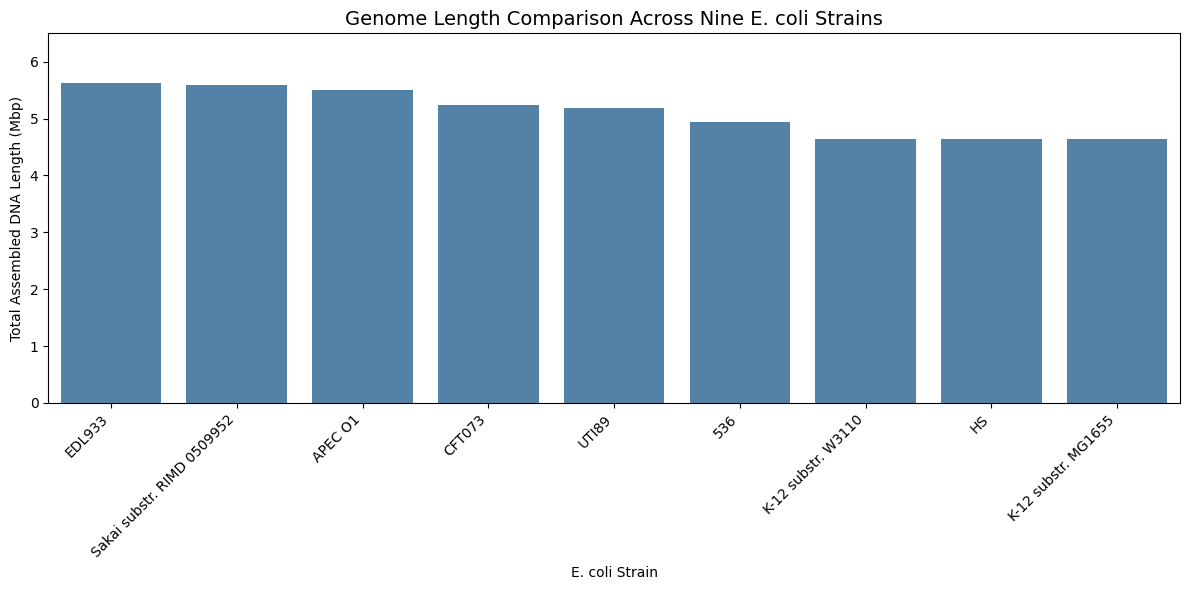

In [28]:

# STEP 23: Genome Length Comparison
# Section 3.3 — Exploratory Visualisations

import matplotlib.pyplot as plt
import seaborn as sns

# Sort genomes by length
plot_df = genome_df.sort_values(
    "total_length_bp",
    ascending=False
).copy()

# Convert base pairs to millions
plot_df["genome_length_mbp"] = (
    plot_df["total_length_bp"] / 1_000_000
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="strain",
    y="genome_length_mbp",
    color="steelblue"
)

plt.title(
    "Genome Length Comparison Across Nine E. coli Strains",
    fontsize=14
)

plt.xlabel("E. coli Strain")
plt.ylabel("Total Assembled DNA Length (Mbp)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 6.5)

plt.tight_layout()
plt.show()


#### Figure 1: Genome Length Comparison

The bar chart illustrates variation in total assembled DNA length among the nine selected *Escherichia coli* strains.

EDL933 had the largest assembled genome at approximately 5.62 million base pairs, while K-12 MG1655 had the smallest at approximately 4.64 million base pairs.

The difference of approximately 0.98 million base pairs demonstrates variation in assembled genomic content across the selected strains.

However, genome length differences alone do not indicate antibiotic resistance. Further investigation of gene content and genomic variation is necessary to determine whether these differences are associated with resistance-related genetic elements.

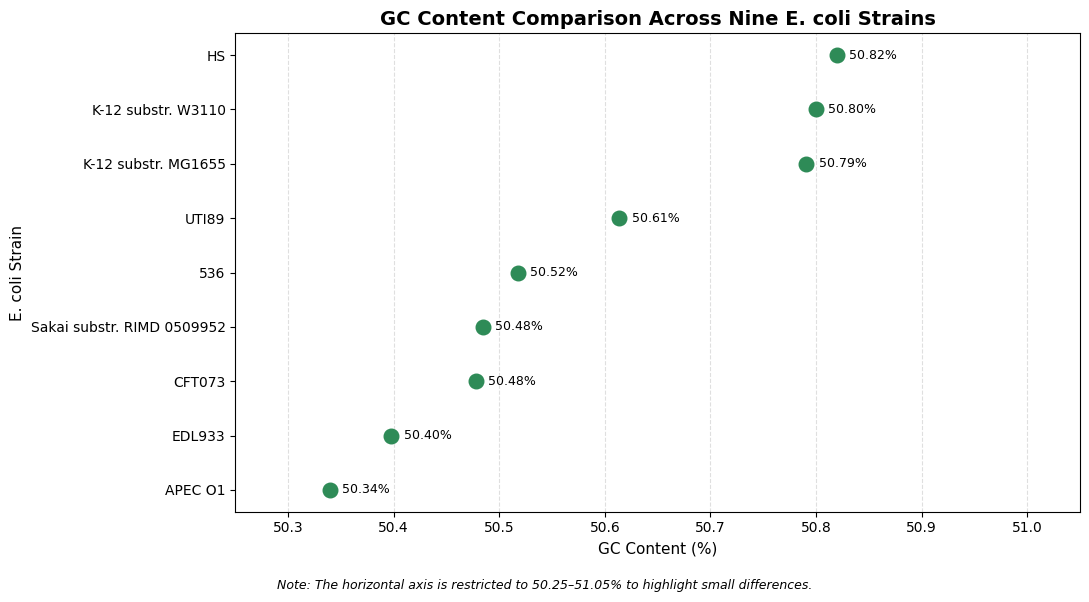

In [31]:

# STEP 24: Revised GC Content Comparison
# Section 3.3 — Exploratory Visualisations

import matplotlib.pyplot as plt

# Sort strains by GC content
plot_gc = genome_df.sort_values(
    "gc_percent",
    ascending=True
).copy()

# Create the figure
plt.figure(figsize=(11, 6))

# Plot GC percentages as points
plt.scatter(
    plot_gc["gc_percent"],
    plot_gc["strain"],
    color="seagreen",
    s=110,
    zorder=3
)

# Add light gridlines for easier comparison
plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

# Add GC percentage labels beside each point
for _, row in plot_gc.iterrows():
    plt.text(
        row["gc_percent"] + 0.012,
        row["strain"],
        f'{row["gc_percent"]:.2f}%',
        va="center",
        fontsize=9
    )

# Chart title and labels
plt.title(
    "GC Content Comparison Across Nine E. coli Strains",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("GC Content (%)", fontsize=11)
plt.ylabel("E. coli Strain", fontsize=11)

# Zoom in to show the small differences clearly
plt.xlim(50.25, 51.05)

# Clearly indicate that the scale is restricted
plt.figtext(
    0.5,
    0.01,
    "Note: The horizontal axis is restricted to 50.25–51.05% "
    "to highlight small differences.",
    ha="center",
    fontsize=9,
    style="italic"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


#### Figure 2: GC Content Comparison

The dot plot compares the GC percentages of the nine selected *Escherichia coli* genome assemblies. A restricted horizontal axis was used to make the relatively small differences between strains easier to observe.

The HS strain recorded the highest GC content at approximately 50.82%, while APEC O1 had the lowest at approximately 50.34%. The difference between the highest and lowest values was approximately 0.48 percentage points.

Overall, the results demonstrate that the selected strains have broadly similar GC composition despite variations in assembled genome length. However, these similarities do not necessarily indicate identical genetic characteristics or evolutionary relationships.

Further comparative genomic analysis is required to determine whether differences in gene content and genetic variation are associated with antibiotic resistance.

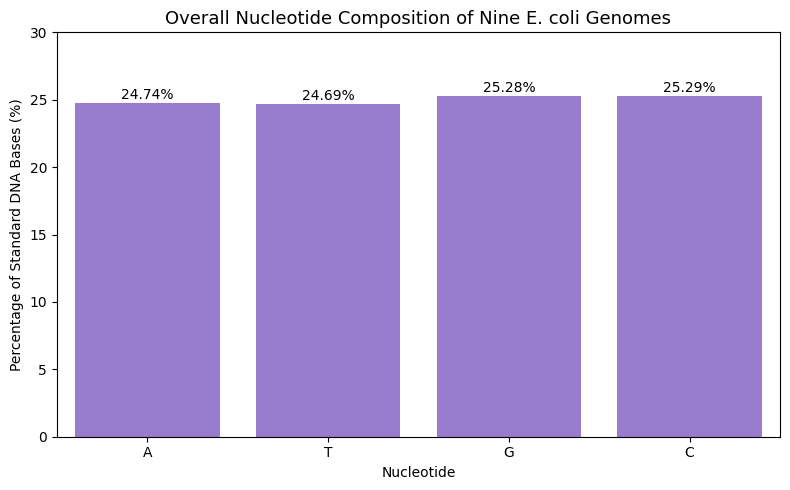

In [30]:

# STEP 25: Overall Nucleotide Composition

plt.figure(figsize=(8, 5))

sns.barplot(
    data=nucleotide_df,
    x="Nucleotide",
    y="Percentage",
    color="mediumpurple"
)

plt.title(
    "Overall Nucleotide Composition of Nine E. coli Genomes",
    fontsize=13
)

plt.xlabel("Nucleotide")
plt.ylabel("Percentage of Standard DNA Bases (%)")

plt.ylim(0, 30)

# Display percentages above the bars
for i, value in enumerate(nucleotide_df["Percentage"]):
    plt.text(
        i,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


#### Figure 3: Overall Nucleotide Composition

The nucleotide composition chart illustrates the relative proportions of adenine, thymine, guanine and cytosine across the nine *Escherichia coli* genome assemblies.

Guanine and cytosine each accounted for approximately 25.3% of the standard nucleotide bases, while adenine and thymine each contributed approximately 24.7%.

The results indicate a relatively balanced nucleotide composition, with a slightly higher combined proportion of guanine and cytosine.

These findings provide a baseline description of the selected genomic sequences for subsequent comparative analysis.

In [32]:

# STEP 27: Export processed genomic datasets

import os

output_folder = "/content/ecoli_analysis_results"
os.makedirs(output_folder, exist_ok=True)

files_to_save = {
    "ecoli_genome_summary.csv": genome_df,
    "ecoli_sequence_summary.csv": sequences_df,
    "ecoli_validation_results.csv": validation_df,
    "ecoli_nucleotide_composition.csv": nucleotide_df
}

for filename, dataframe in files_to_save.items():
    file_path = os.path.join(output_folder, filename)
    dataframe.to_csv(file_path, index=False)
    print(f"Saved: {filename} ({len(dataframe)} rows)")

print("\nAll processed datasets exported successfully.")


Saved: ecoli_genome_summary.csv (9 rows)
Saved: ecoli_sequence_summary.csv (15 rows)
Saved: ecoli_validation_results.csv (9 rows)
Saved: ecoli_nucleotide_composition.csv (4 rows)

All processed datasets exported successfully.


In [33]:

# STEP 28: Download processed datasets as a ZIP file

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/ecoli_analysis_results",
    "zip",
    output_folder
)

print("ZIP file created:", zip_path)

files.download(zip_path)


ZIP file created: /content/ecoli_analysis_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

# STEP 30: Final Dataset Validation
# Check that the processed datasets are consistent

print("=== FINAL DATASET VALIDATION ===")

checks = {
    "Nine genome assemblies available": len(genome_df) == 9,

    "Fifteen DNA sequence records available":
        len(sequences_df) == 15,

    "No duplicate assembly accessions":
        genome_df["assembly_accession"].is_unique,

    "No missing genome summary values":
        not genome_df.isnull().any().any(),

    "All genome lengths match NCBI":
        validation_df["length_difference"].eq(0).all(),

    "All nine assemblies have NCBI comparison values":
        validation_df[
            ["ncbi_length", "ncbi_gc_percent"]
        ].notna().all().all(),

    "Nucleotide percentages total approximately 100%":
        abs(nucleotide_df["Percentage"].sum() - 100) < 0.001
}

for check, passed in checks.items():
    status = "PASS" if passed else "REVIEW"
    print(f"{status}: {check}")

if all(checks.values()):
    print("\nAll final validation checks passed.")
else:
    print("\nSome checks require further review.")


=== FINAL DATASET VALIDATION ===
PASS: Nine genome assemblies available
PASS: Fifteen DNA sequence records available
PASS: No duplicate assembly accessions
PASS: No missing genome summary values
PASS: All genome lengths match NCBI
PASS: All nine assemblies have NCBI comparison values
PASS: Nucleotide percentages total approximately 100%

All final validation checks passed.


#### Final Dataset Validation

A final validation was performed to confirm the consistency of the processed genomic datasets. All seven validation checks passed, confirming the presence of nine genome assemblies and 15 DNA sequence records, with no duplicate assembly accessions or missing values in the genome-level summary. All calculated genome lengths matched the corresponding NCBI assembly statistics, and nucleotide composition percentages summed to approximately 100%.

These results confirm that the prepared datasets satisfy the defined consistency checks and are suitable for subsequent comparative genomic analysis, subject to the identified limitations concerning sequence ambiguity and assembly classification.

### References and Data Sources

**Dataset Source**

National Center for Biotechnology Information (NCBI). (n.d.). *NCBI Datasets: Genome*. National Library of Medicine. https://www.ncbi.nlm.nih.gov/datasets/genome/

National Center for Biotechnology Information (NCBI). (n.d.). *Get genome metadata*. NCBI Datasets Documentation. https://www.ncbi.nlm.nih.gov/datasets/docs/v2/how-tos/genomes/get-genome-metadata/

**Genome Assemblies Used**

The study used the following nine *Escherichia coli* RefSeq genome assemblies:

| Strain | RefSeq Assembly Accession |
|---|---|
| K-12 MG1655 | GCF_000005845.2 |
| EDL933 | GCF_000006665.1 |
| CFT073 | GCF_000007445.1 |
| Sakai RIMD 0509952 | GCF_000008865.2 |
| K-12 W3110 | GCF_000010245.2 |
| UTI89 | GCF_000013265.1 |
| 536 | GCF_000013305.1 |
| APEC O1 | GCF_000014845.1 |
| HS | GCF_000017765.1 |

**Bioinformatics Software Reference**

Cock, P. J. A., et al. (2009). Biopython: Freely available Python tools for computational molecular biology and bioinformatics. *Bioinformatics, 25*(11), 1422–1423. https://doi.org/10.1093/bioinformatics/btp163

**Analysis Environment**

Google Colab was used to execute Python code for sequence processing, data-quality assessment, descriptive statistics and exploratory visualisation. The analysis used Biopython, pandas, Matplotlib and Seaborn.

**Data Attribution**

All genomic sequence data and associated assembly metadata were obtained from NCBI RefSeq. The calculated statistics, validation tables and visualisations were generated by Group 2 from these downloaded records.